# Preprocesamiento de datos
*(Etapa: Data Lake -> Data Pipeline + Feature engineering)*


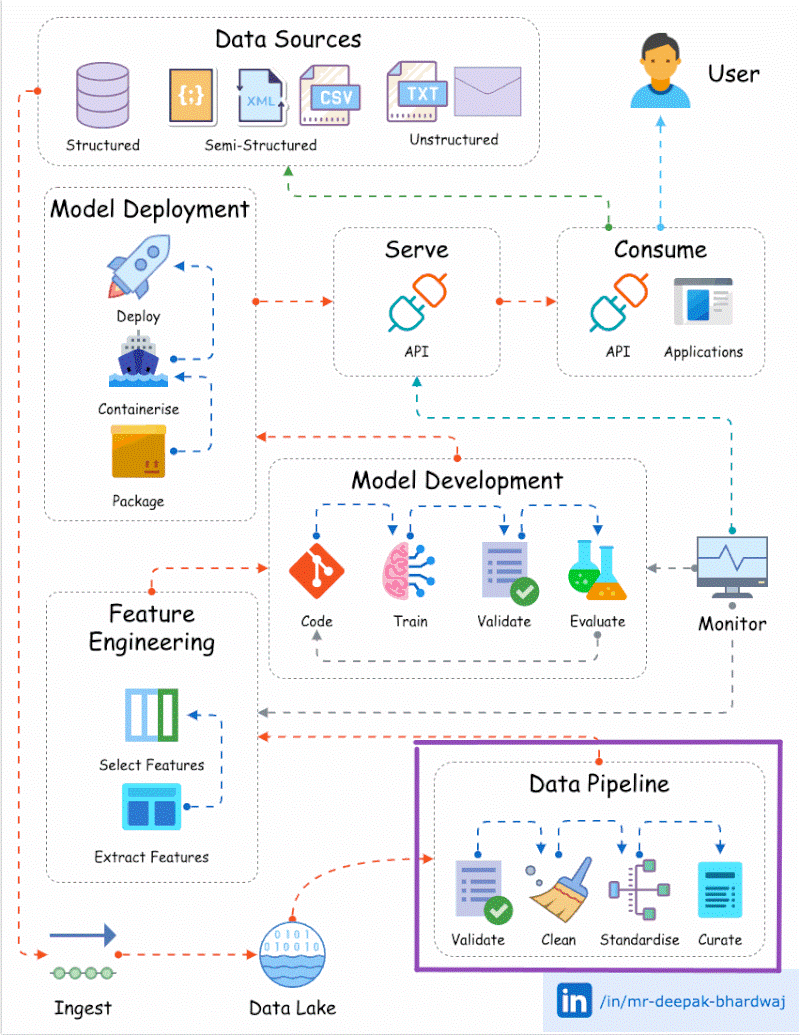

In [ ]:
# Bibliotecas

import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy.stats import chi2_contingency

In [ ]:
# Definiciones globales

%run ../Lib/pandas_options.py
%run ../Lib/define_constantes.py

In [ ]:
# Cargar datos de tramos calificados

archivo_tramos_calificados = f'{DIRECTORIO_RESULTADOS}/TRAMOSCALIFICADOS_2024-11.csv'
df_tramos_calificados = pd.read_csv(archivo_tramos_calificados, low_memory=False)



---


# Analítica de datos

In [ ]:
# Revisar datos cargados

print(df_tramos_calificados.info())
display(df_tramos_calificados.describe())

## Procedimientos para visualización de estadísticas

In [ ]:
# ------------------------------------------------------------------------------------------------------------------------
def visualizar_distribucion(lista_columnas, df, titulo='Distribuciones'):
    sns.set(style='whitegrid')
    fig, axes = plt.subplots(2, len(lista_columnas), figsize=(16, 8))

    for i, columna in enumerate(lista_columnas):
        if df[columna].dtype == bool:
            sns.countplot(x=columna, data=df, ax=axes[0, i])
            axes[0, i].set_xlabel(columna, fontsize=10, fontweight='bold')
            axes[0, i].set_ylabel('Cantidad' if i == 0 else '', fontsize=10, fontweight='bold')
            axes[0, i].tick_params(labelsize=8)
        else:
            sns.boxplot(x=df[columna], ax=axes[0, i])
            axes[0, i].set_xlabel(columna, fontsize=10, fontweight='bold')
            axes[0, i].set_ylabel('Valores' if i == 0 else '', fontsize=10, fontweight='bold')
            axes[0, i].tick_params(labelsize=8)


        sns.histplot(data=df, x=columna, kde=True, ax=axes[1, i])
        axes[1, i].set_xlabel('')
        axes[1, i].set_ylabel('Frecuencia' if i == 0 else '', fontsize=10, fontweight='bold')
        axes[1, i].tick_params(labelsize=8)

    fig.suptitle(titulo, fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.show()

# -----------------------------------------------------------------------------------------------------------------------
def visualizar_correlaciones(lista_columnas, df, titulo='Matriz de correlaciones'):
    matriz_correlaciones = df[lista_columnas].corr()

    plt.figure(figsize=(14, 4))
    sns.set(font_scale=1)

    mascara = np.triu(np.ones(matriz_correlaciones.shape), k=1) # Ocultar diagonal superior
    mapa = sns.heatmap(matriz_correlaciones, annot=True, cmap='seismic', center=0, vmin=-1, vmax=1, mask=mascara, linewidths=0)
    mapa.set_facecolor('none')

    plt.title(titulo, fontsize=12, fontweight='bold')
    plt.show()

# ----------------------------------------------------------------------------------------------------------------------
def visualizar_matriz_dispersion(lista_columnas, df, nombre_columna_clasificadora, titulo='Matriz de dispersión'):
    tipo_versus = df[nombre_columna_clasificadora].dtype
    paleta = {False: 'lightgreen', True: 'red'} if tipo_versus == bool else {0: 'black', 1: 'lightgreen', 2: 'lightblue', 3: 'yellow', 4: 'orange', 5: 'red'}

    malla = sns.pairplot(
        df,
        vars=lista_columnas,
        hue=nombre_columna_clasificadora,
        palette=paleta,
    )

    malla.fig.suptitle(titulo, y=1.02, fontsize=12, fontweight='bold')
    malla.fig.set_facecolor('lightgray')
    plt.show()

# ---------------------------------------------------------------------------------------------------------------------
def visualizar_distribucion_categoricas(lista_columnas, nombre_col_comparacion, df, titulo=''):
    fig, axes = plt.subplots(nrows=int(len(lista_columnas) / 2 + 0.5), ncols=2, figsize=(14, 2 * len(lista_columnas)))
    axes = axes.flat

    tipo_versus = df[nombre_col_comparacion].dtype
    paleta = {False: 'lightgreen', True: 'red'} if tipo_versus == bool else {0: 'black', 1: 'lightgreen', 2: 'lightblue', 3: 'yellow', 4: 'orange', 5: 'red'}

    for i, columna in enumerate(lista_columnas):
        tabla = pd.crosstab(df[columna], df[nombre_col_comparacion])
        sums = tabla.sum(axis=1)
        sorted_indices = sums.sort_values().index
        tabla.loc[sorted_indices].plot(
            kind='barh',
            stacked=True,
            ax=axes[i],
            color=[paleta[col] for col in tabla.columns],
            legend=False
        )
        axes[i].set_title(f'{nombre_col_comparacion} vs {columna}', fontsize=10, fontweight='bold')
        axes[i].tick_params(labelsize=8)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')

    # Eliminar el último eje si hay un número impar de columnas
    if len(lista_columnas) % 2 != 0:
        fig.delaxes(axes[-1])

    fig.suptitle(titulo, y=1.02, fontsize=12, fontweight='bold')
    fig.tight_layout()
    etiquetas = [f"{k}" for k in paleta.keys()]
    fig.legend(etiquetas, title=nombre_col_comparacion, loc='center right', bbox_to_anchor=(1.1, 0.5))
    plt.show()

# ---------------------------------------------------------------------------------------------------------------------
def visualizar_correlaciones_categoricas(lista_columnas, df, alpha=0.001, titulo=''):
    matriz = []
    for i, c1 in enumerate(lista_columnas):
        matriz.append([])
        for j, c2 in enumerate(lista_columnas):
            p = chi2_contingency(pd.crosstab(df[c1], df[c2])).pvalue if i != j else 0
            matriz[i].append(p)

    plt.figure(figsize=(15, 5))
    sns.set(font_scale=0.8)
    mascara = np.triu(np.ones(len(lista_columnas)), k=1) # Ocultar diagonal superior
    mapa = sns.heatmap(
        matriz,
        xticklabels=lista_columnas,
        yticklabels=lista_columnas,
        annot=True,
        fmt=".3e",
        mask=mascara,
        cmap="rocket_r",
        vmax=alpha,
    )

    mapa.set_facecolor('none')
    plt.title(titulo, fontsize=12, fontweight='bold')
    plt.show()



# Análisis exploratorio

## Variables numéricas:

Conclusiones:

*   DIAMETRO: Entre 100 mm y 2000 mm, y convertir a metros para unificar unidades
*   LONGITUD: Entre 1 mt y 250 mt
*   PROF_BATEA, PROF_BATE1: <= 150 mt
*   PENDIENTE: Recalcular con PROF_BATEA, PROF_BATE1 Y LONGITUD
*   EDAD: 0-100 años
*   Normalizar valores numéricos entre 0-1
*   AREA: Categoría nueva, calculada como DIAMETRO x LONGITUD x PI








In [ ]:
# Crear temporalmente característica EDAD para el análisis exploratorio de variables numéricas

df_tramos_calificados_con_edad = df_tramos_calificados.assign(
    EDAD=df_tramos_calificados['FECHA_INST'].apply(
        lambda fecha: (datetime.now() - pd.to_datetime(fecha)).total_seconds() / (365 * 24 * 60 * 60)
    )
)

numericas_a_explorar = ['EDAD', 'DIAMETRO', 'LONGITUD', 'PROF_BATEA', 'PROF_BATE1', 'PENDIENTE', 'CALIFICACION']

In [ ]:
visualizar_distribucion(
    numericas_a_explorar,
    df_tramos_calificados_con_edad,
    titulo='Estadísticas de distribución ANTES de preprocesamiento'
)

In [ ]:
visualizar_correlaciones(
    numericas_a_explorar,
    df_tramos_calificados_con_edad,
    titulo='Matriz de correlaciones ANTES de preprocesamiento'
)

In [ ]:
visualizar_matriz_dispersion(
    [c for c in numericas_a_explorar if c != 'CALIFICACION'],
    df_tramos_calificados_con_edad,
    nombre_columna_clasificadora='CALIFICACION',
    titulo='Matriz de dispersión ANTES de preprocesamiento'
)

## Variables categóricas

Conclusiones:

* TIPO_RED: Eliminar por mínima representación de categorías minoritarias y baja correlacion con CALIFICACION.
* TIPO_AGUA: Unificar categorias LLUVIAS y DESCARGAS.
* TIPO_CIMEN: Descartada, valores no estandarizados.
* TIPO_SUELO: Descartada, valores no estandarizados.
* MATERIAL: Unificar concreto simple, pvc. Incluir OTROS con concretos reforzados.
* FABRICANTE: MAntener los top-2 y unifcar los demás en "OTROS".
* CAMARA_CAI: Eliminar, tiene solamente dos categorías y el valor "SI" no esta suficientemente representado.
* ZONA: Reclasificar nulos en NORTE+N/D.
* MUNICIPIO: Reclasificar en MEDELLIN y los demás en OTROS.
* ESTADO: Descartada, clases minoritarias escasamente representadas.
* CALIFICACION: Binarizar convirtiendo a DETERIORADO, en donde 1-3 es False(Bueno, no deteriorado) y 4-5 es True(Deteriorado)

In [ ]:
# Definir columnas categóricas para exploración inicial
categoricas_a_explorar = [
    'TIPO_RED',   'TIPO_AGUA',
    'TIPO_CIMEN', 'TIPO_SUELO',
    'MATERIAL',   'FABRICANTE',
    'ARRANQUE',   'CAMARA_CAI',
    'ZONA',       'MUNICIPIO',
    'ESTADO',
]

In [ ]:
visualizar_distribucion_categoricas(
    categoricas_a_explorar,
    'CALIFICACION',
    df_tramos_calificados,
    titulo='Distribución de variables categóricas ANTES de preprocesamiento'
)

In [ ]:
visualizar_correlaciones_categoricas(
    categoricas_a_explorar + ['CALIFICACION'],
    df_tramos_calificados,
    alpha=1e-10,
    titulo=f'Matriz de correlaciones categóricas ANTES de preprocesamiento'
)



---


# Operaciones de preprocesamiento


## Funciones de transformación

In [ ]:
%run ../Lib/fn_transformaciones.py

## Secuencia de transformaciones

In [ ]:
# Aplicar secuencia de operaciones

df_datos_preprocesados = tx_aplicar_transformaciones(df_tramos_calificados)



---


## Revisión de datos preprocesados

In [ ]:
print(df_datos_preprocesados.info())
print('-'*80)
display(df_datos_preprocesados.describe(include='all'))

columnas_categoricas = list(df_datos_preprocesados.select_dtypes(include=['object', 'bool']).columns)
columnas_categoricas.remove('DETERIORADO')
columnas_numericas = list(df_datos_preprocesados.select_dtypes(include=['int', 'float']).columns)
for columna in columnas_categoricas:
    print('-' * 80)
    print(columna)
    print(df_datos_preprocesados[columna].value_counts())

# Encontrar columnas candidatas a binarización
# columnas_binarias = [col for col in columnas_categoricas if df_datos_preprocesados[col].nunique() == 2]
# print('-' * 80)
# print('Columnas categóricas con solamente dos categorias:')
# for col in columnas_binarias:
#     valores = df_datos_preprocesados[col].unique()
#     print(f'{col}: {valores}')

In [ ]:
visualizar_distribucion(
    columnas_numericas + ['DETERIORADO'],
    df_datos_preprocesados,
    titulo='Estadísticas de distribución DESPUÉS de preprocesamiento'
)

In [ ]:
visualizar_correlaciones(
    columnas_numericas + ['DETERIORADO'],
    df_datos_preprocesados,
    titulo='Matriz de correlaciones DESPUÉS de preprocesamiento'
)

In [ ]:
visualizar_matriz_dispersion(
    columnas_numericas,
    df_datos_preprocesados,
    nombre_columna_clasificadora='DETERIORADO',
    titulo='Matriz de dispersión DESPUÉS de preprocesamiento'
)

In [ ]:
visualizar_distribucion_categoricas(
    columnas_categoricas,
    'DETERIORADO',
    df_datos_preprocesados,
    titulo='Distribución de variables categóricas DESPUÉS de preprocesamiento'
)

In [ ]:
visualizar_correlaciones_categoricas(
    columnas_categoricas + ['DETERIORADO'],
    df_datos_preprocesados,
    alpha=1e-10,
    titulo=f'Matriz de correlaciones categóricas DESPUÉS de preprocesamiento'
)

# Codificación de datos

In [ ]:
df_datos_codificados = tx_codificar(df_datos_preprocesados)
print(df_datos_codificados.info())

# Guardar datos preprocesados

In [ ]:
archivo_datos_codificados = f'{DIRECTORIO_RESULTADOS}/DATOSCODIFICADOS_2024-11.csv'
df_datos_codificados.to_csv(archivo_datos_codificados, index=False)
print(f'Guardado {archivo_datos_codificados}')